In [3]:
import xarray as xr
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
import xesmf as xe 
import numpy as np

In [4]:
vec=gpd.read_file("./gadm41_ETH_1.shp")

In [5]:
ds=xr.open_dataset("/home/mesay/Desktop/ACACIA/S2S_Data/ECMWF/tp/tp_ECMWF_20260914_15.0N_33.0E_3.0N_48.0E_fc.nc")
ds=ds.rename({"latitude":"lat","longitude":"lon"})
fc=ds["tp"]

ds=xr.open_dataset("/home/mesay/Desktop/ACACIA/S2S_Data/ECMWF/tp/tp_ECMWF_20260914_15.0N_33.0E_3.0N_48.0E_hc.nc")
ds=ds.rename({"latitude":"lat","longitude":"lon"})
hc=ds["tp"]

ds=xr.open_dataset("./pr_day_chirps-p025_ethiopia_2006-2026.nc")
obs=ds["pr"]

In [12]:

ds=xr.open_dataset("./pr_day_chirps-p025_ethiopia_2006-2026.nc")
obs=ds["pr"]
print(ds)
import xarray as xr

ds = xr.open_dataset("./pr_day_chirps-p025_ethiopia_2006-2026.nc")
obs = ds["pr"]

# Extract unique lists
unique_years = sorted(list(set(obs["time"].dt.year.values)))
unique_months = sorted(list(set(obs["time"].dt.month.values)))
unique_days = sorted(list(set(obs["time"].dt.day.values)))

print("Years:", unique_years)
print("Number of Years:", len(unique_years))
print("Months:", unique_months)
print("Days:", unique_days)

<xarray.Dataset> Size: 86MB
Dimensions:      (time: 7456, lat: 48, lon: 60)
Coordinates:
  * time         (time) datetime64[ns] 60kB 2006-01-01 2006-01-02 ... 2026-05-31
  * lat          (lat) float64 384B 14.87 14.62 14.37 ... 3.625 3.375 3.125
  * lon          (lon) float64 480B 32.63 32.88 33.13 ... 46.88 47.13 47.38
    spatial_ref  int64 8B ...
Data variables:
    pr           (time, lat, lon) float32 86MB ...
Attributes:
    title:             CHIRPS v2.0 rainfall data
    summary:           CHIRPS v2.0 rainfall data downloaded from https://data...
    history:           2026-07-07 23:09:57: converted from original tif forma...
    contributor_name:  SADC Climate Services Centre (CSC)
    contributor_role:  downloaded and harmonized data
Years: [np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020)

In [6]:
#inspecting data
hc

<xarray.DataArray 'tp' (time: 540, member: 22, lat: 9, lon: 11)> Size: 5MB
[1176120 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 4kB 2006-09-15 2006-09-16 ... 2025-10-11
  * lat      (lat) float64 72B 15.0 13.5 12.0 10.5 9.0 7.5 6.0 4.5 3.0
  * lon      (lon) float64 88B 33.0 34.5 36.0 37.5 39.0 ... 43.5 45.0 46.5 48.0
    surface  float64 8B ...
Dimensions without coordinates: member
Attributes: (12/31)
    GRIB_paramId:                             228228
    GRIB_dataType:                            pf
    GRIB_numberOfPoints:                      99
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_shortName:                           tp
    GRIB_totalNumber:                         11
    GRIB_units:                               kg m**-2
    long_name:                                Total Precipitation
    units:                                    kg m**-2
    standard_name:                            unknown

Text(0.5, 0.98, 'just illustrating spatial patterns')

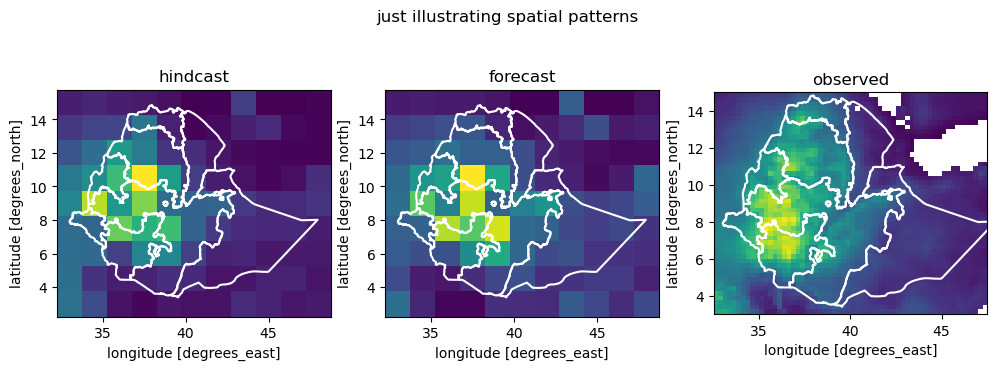

In [7]:
fig=plt.figure(figsize=(12,4))
pl=fig.add_subplot(1,3,1)
hc.mean(["time","member"]).plot(ax=pl, add_colorbar=False)
vec.boundary.plot(ax=pl,color="white")
pl.set_title("hindcast")

pl=fig.add_subplot(1,3,2)
fc.mean(["time","member"]).plot(ax=pl, add_colorbar=False)
vec.boundary.plot(ax=pl,color="white")
pl.set_title("forecast")

pl=fig.add_subplot(1,3,3)
obs.mean(["time"]).plot(ax=pl, add_colorbar=False)
vec.boundary.plot(ax=pl,color="white")
pl.set_title("observed")
plt.suptitle("just illustrating spatial patterns")

In [9]:
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 1. PRE-COMPUTE MEANS & FIND UNIFIED COLOR LIMITS (The "Smart" Way)
# -------------------------------------------------------------------------
# Pre-calculate means so we can extract exact min/max limits
mean_hcd = hcd.mean(["time", "member"])
mean_fcd = fcd.mean(["time", "member"])
mean_obsr = obsr.mean(["time"])
mean_obs = obs.mean(["time"])

# Compute a single, honest scale so colors mean the exact same thing across maps
vmin = min(mean_hcd.min(), mean_fcd.min(), mean_obsr.min(), mean_obs.min()).item()
vmax = max(mean_hcd.max(), mean_fcd.max(), mean_obsr.max(), mean_obs.max()).item()

# -------------------------------------------------------------------------
# 2. GRAPHICS DESIGN & GRID SETUP
# -------------------------------------------------------------------------
# Setup whitegrid if available
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Create a figure with shared axes to keep them perfectly aligned
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), sharex=True, sharey=True)

fig.suptitle(
    "S2S Verification — Spatial Patterns Comparison", 
    fontsize=16, weight='bold', color='#0f172a', y=1.05
)

# Common plotting configurations
# Tip: Choose a colormap that suits your data (e.g., "Blues" for precip, "YlOrRd" for temp)
plot_kwargs = {
    "vmin": vmin,
    "vmax": vmax,
    "cmap": "viridis",  # Swap to "Blues", "YlOrRd", or "Spectral_r" depending on your variable!
    "add_colorbar": False
}

# -------------------------------------------------------------------------
# 3. POPULATE SUBPLOTS
# -------------------------------------------------------------------------
# Subplot 1: Hindcast
im = mean_hcd.plot(ax=axes[0], **plot_kwargs)
vec.boundary.plot(ax=axes[0], color="white", linewidth=1.2, zorder=2)
axes[0].set_title("Hindcast (Mean)", fontsize=12, weight='semibold', color='#1e293b')

# Subplot 2: Forecast
mean_fcd.plot(ax=axes[1], **plot_kwargs)
vec.boundary.plot(ax=axes[1], color="white", linewidth=1.2, zorder=2)
axes[1].set_title("Forecast (Mean)", fontsize=12, weight='semibold', color='#1e293b')

# Subplot 3: Observed Regridded
mean_obsr.plot(ax=axes[2], **plot_kwargs)
vec.boundary.plot(ax=axes[2], color="white", linewidth=1.2, zorder=2)
axes[2].set_title("Observed (Regridded)", fontsize=12, weight='semibold', color='#1e293b')

# Subplot 4: Observed Original
mean_obs.plot(ax=axes[3], **plot_kwargs)
vec.boundary.plot(ax=axes[3], color="white", linewidth=1.2, zorder=2)
axes[3].set_title("Observed (Original)", fontsize=12, weight='semibold', color='#1e293b')

# -------------------------------------------------------------------------
# 4. AXES & GRID CLEANUP
# -------------------------------------------------------------------------
for i, ax in enumerate(axes):
    ax.set_xlabel("Longitude", fontsize=10, color='#64748b', labelpad=8)
    
    # Only show Y label/ticks on the left-most plot to maximize data space
    if i == 0:
        ax.set_ylabel("Latitude", fontsize=10, color='#64748b')
    else:
        ax.set_ylabel("")
        ax.tick_params(labelleft=False)
        
    ax.tick_params(colors='#64748b', labelsize=9)
    ax.grid(True, linestyle=":", alpha=0.5, color="#cbd5e1")

# -------------------------------------------------------------------------
# 5. UNIFIED COLORBAR (Legend)
# -------------------------------------------------------------------------
# Compress the subplots slightly to make elegant room for the vertical colorbar
fig.subplots_adjust(right=0.88, wspace=0.12)

# [left, bottom, width, height] as fraction of figure size
cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7]) 
cbar = fig.colorbar(im, cax=cbar_ax)

# Label your colorbar based on your variable
cbar.set_label("Variable Magnitude (Units)", fontsize=11, weight='bold', color='#0f172a', labelpad=12)
cbar.ax.tick_params(labelsize=9, colors='#475569')
cbar.outline.set_visible(False)

plt.show()

NameError: name 'hcd' is not defined

Text(0.5, 0.98, 'just illustrating temporal patterns')

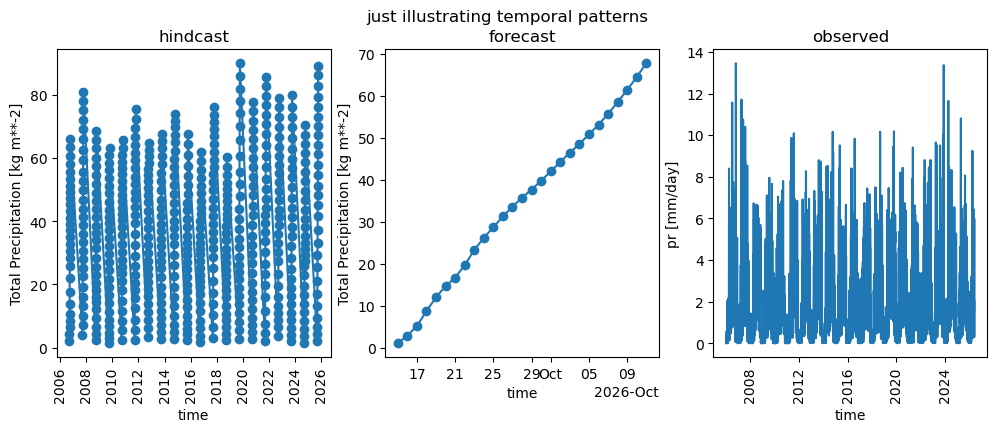

In [10]:
fig=plt.figure(figsize=(12,4))
pl=fig.add_subplot(1,3,1)
hc.mean(["lat","lon","member"]).plot(ax=pl, marker="o")
pl.set_title("hindcast")
plt.xticks(rotation=90)

pl=fig.add_subplot(1,3,2)
fc.mean(["lat","lon","member"]).plot(ax=pl, marker="o")
pl.set_title("forecast")

pl=fig.add_subplot(1,3,3)
obs.mean(["lat","lon"]).plot(ax=pl)
pl.set_title("observed")
plt.xticks(rotation=90)

plt.suptitle("just illustrating temporal patterns")

In [11]:
# understanding forecast data
# note - forecast is initialized on 3 June at 00:00
# first time value is on 4th at 00:00
# value at 00:00 is taken from hourly data, and denotes a value at the end of the computational step
# because this is accumulated rainfall, value at 00:00 denotes rainfall accumulated over the PREVIOUS 24 hours. 
# so value on the 2026-06-04 00:00 is actually rainfall over 2026-06-03
fc.time

<xarray.DataArray 'time' (time: 27)> Size: 216B
array(['2026-09-15T00:00:00.000000000', '2026-09-16T00:00:00.000000000',
       '2026-09-17T00:00:00.000000000', '2026-09-18T00:00:00.000000000',
       '2026-09-19T00:00:00.000000000', '2026-09-20T00:00:00.000000000',
       '2026-09-21T00:00:00.000000000', '2026-09-22T00:00:00.000000000',
       '2026-09-23T00:00:00.000000000', '2026-09-24T00:00:00.000000000',
       '2026-09-25T00:00:00.000000000', '2026-09-26T00:00:00.000000000',
       '2026-09-27T00:00:00.000000000', '2026-09-28T00:00:00.000000000',
       '2026-09-29T00:00:00.000000000', '2026-09-30T00:00:00.000000000',
       '2026-10-01T00:00:00.000000000', '2026-10-02T00:00:00.000000000',
       '2026-10-03T00:00:00.000000000', '2026-10-04T00:00:00.000000000',
       '2026-10-05T00:00:00.000000000', '2026-10-06T00:00:00.000000000',
       '2026-10-07T00:00:00.000000000', '2026-10-08T00:00:00.000000000',
       '2026-10-09T00:00:00.000000000', '2026-10-10T00:00:00.000000000',
       '2026-10-11T00:00:00.000000000'], dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 216B 2026-09-15 2026-09-16 ... 2026-10-11
    surface  float64 8B ...
Attributes:
    standard_name:  time
    long_name:      time

In [12]:
# understanding forecast data
# note - forecast is initialized on 3 June at 00:00
# first time value is on 4th at 00:00
# value at 00:00 is taken from hourly data, and denotes a value at the end of the computational step
# because this is accumulated rainfall, value at 00:00 denotes rainfall accumulated over the PREVIOUS 24 hours. 
# so value on the 2026-06-04 00:00 is actually rainfall over 2026-06-03
fc.time

<xarray.DataArray 'time' (time: 27)> Size: 216B
array(['2026-09-15T00:00:00.000000000', '2026-09-16T00:00:00.000000000',
       '2026-09-17T00:00:00.000000000', '2026-09-18T00:00:00.000000000',
       '2026-09-19T00:00:00.000000000', '2026-09-20T00:00:00.000000000',
       '2026-09-21T00:00:00.000000000', '2026-09-22T00:00:00.000000000',
       '2026-09-23T00:00:00.000000000', '2026-09-24T00:00:00.000000000',
       '2026-09-25T00:00:00.000000000', '2026-09-26T00:00:00.000000000',
       '2026-09-27T00:00:00.000000000', '2026-09-28T00:00:00.000000000',
       '2026-09-29T00:00:00.000000000', '2026-09-30T00:00:00.000000000',
       '2026-10-01T00:00:00.000000000', '2026-10-02T00:00:00.000000000',
       '2026-10-03T00:00:00.000000000', '2026-10-04T00:00:00.000000000',
       '2026-10-05T00:00:00.000000000', '2026-10-06T00:00:00.000000000',
       '2026-10-07T00:00:00.000000000', '2026-10-08T00:00:00.000000000',
       '2026-10-09T00:00:00.000000000', '2026-10-10T00:00:00.000000000',
       '2026-10-11T00:00:00.000000000'], dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 216B 2026-09-15 2026-09-16 ... 2026-10-11
    surface  float64 8B ...
Attributes:
    standard_name:  time
    long_name:      time

In [13]:
# understanding forecast data
# note - forecast is initialized on 3 June at 00:00
# first time value is on 4th at 00:00
# value at 00:00 is taken from hourly data, and denotes a value at the end of the computational step
# because this is accumulated rainfall, value at 00:00 denotes rainfall accumulated over the PREVIOUS 24 hours. 
# so value on the 2026-06-04 00:00 is actually rainfall over 2026-06-03
fc.time

<xarray.DataArray 'time' (time: 27)> Size: 216B
array(['2026-09-15T00:00:00.000000000', '2026-09-16T00:00:00.000000000',
       '2026-09-17T00:00:00.000000000', '2026-09-18T00:00:00.000000000',
       '2026-09-19T00:00:00.000000000', '2026-09-20T00:00:00.000000000',
       '2026-09-21T00:00:00.000000000', '2026-09-22T00:00:00.000000000',
       '2026-09-23T00:00:00.000000000', '2026-09-24T00:00:00.000000000',
       '2026-09-25T00:00:00.000000000', '2026-09-26T00:00:00.000000000',
       '2026-09-27T00:00:00.000000000', '2026-09-28T00:00:00.000000000',
       '2026-09-29T00:00:00.000000000', '2026-09-30T00:00:00.000000000',
       '2026-10-01T00:00:00.000000000', '2026-10-02T00:00:00.000000000',
       '2026-10-03T00:00:00.000000000', '2026-10-04T00:00:00.000000000',
       '2026-10-05T00:00:00.000000000', '2026-10-06T00:00:00.000000000',
       '2026-10-07T00:00:00.000000000', '2026-10-08T00:00:00.000000000',
       '2026-10-09T00:00:00.000000000', '2026-10-10T00:00:00.000000000',
       '2026-10-11T00:00:00.000000000'], dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 216B 2026-09-15 2026-09-16 ... 2026-10-11
    surface  float64 8B ...
Attributes:
    standard_name:  time
    long_name:      time

In [14]:
# understanding forecast data
# note - forecast is initialized on 3 June at 00:00
# first time value is on 4th at 00:00
# value at 00:00 is taken from hourly data, and denotes a value at the end of the computational step
# because this is accumulated rainfall, value at 00:00 denotes rainfall accumulated over the PREVIOUS 24 hours. 
# so value on the 2026-06-04 00:00 is actually rainfall over 2026-06-03
fc.time

<xarray.DataArray 'time' (time: 27)> Size: 216B
array(['2026-09-15T00:00:00.000000000', '2026-09-16T00:00:00.000000000',
       '2026-09-17T00:00:00.000000000', '2026-09-18T00:00:00.000000000',
       '2026-09-19T00:00:00.000000000', '2026-09-20T00:00:00.000000000',
       '2026-09-21T00:00:00.000000000', '2026-09-22T00:00:00.000000000',
       '2026-09-23T00:00:00.000000000', '2026-09-24T00:00:00.000000000',
       '2026-09-25T00:00:00.000000000', '2026-09-26T00:00:00.000000000',
       '2026-09-27T00:00:00.000000000', '2026-09-28T00:00:00.000000000',
       '2026-09-29T00:00:00.000000000', '2026-09-30T00:00:00.000000000',
       '2026-10-01T00:00:00.000000000', '2026-10-02T00:00:00.000000000',
       '2026-10-03T00:00:00.000000000', '2026-10-04T00:00:00.000000000',
       '2026-10-05T00:00:00.000000000', '2026-10-06T00:00:00.000000000',
       '2026-10-07T00:00:00.000000000', '2026-10-08T00:00:00.000000000',
       '2026-10-09T00:00:00.000000000', '2026-10-10T00:00:00.000000000',
       '2026-10-11T00:00:00.000000000'], dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 216B 2026-09-15 2026-09-16 ... 2026-10-11
    surface  float64 8B ...
Attributes:
    standard_name:  time
    long_name:      time

In [15]:
#the easiest way to convert data from accumulated to daily is to use .diff() which calculates differences between consecutive time steps
#when we do this we get:
# the first value becomes 2026-05-05 00:00
fc.diff("time").time

<xarray.DataArray 'time' (time: 26)> Size: 208B
array(['2026-09-16T00:00:00.000000000', '2026-09-17T00:00:00.000000000',
       '2026-09-18T00:00:00.000000000', '2026-09-19T00:00:00.000000000',
       '2026-09-20T00:00:00.000000000', '2026-09-21T00:00:00.000000000',
       '2026-09-22T00:00:00.000000000', '2026-09-23T00:00:00.000000000',
       '2026-09-24T00:00:00.000000000', '2026-09-25T00:00:00.000000000',
       '2026-09-26T00:00:00.000000000', '2026-09-27T00:00:00.000000000',
       '2026-09-28T00:00:00.000000000', '2026-09-29T00:00:00.000000000',
       '2026-09-30T00:00:00.000000000', '2026-10-01T00:00:00.000000000',
       '2026-10-02T00:00:00.000000000', '2026-10-03T00:00:00.000000000',
       '2026-10-04T00:00:00.000000000', '2026-10-05T00:00:00.000000000',
       '2026-10-06T00:00:00.000000000', '2026-10-07T00:00:00.000000000',
       '2026-10-08T00:00:00.000000000', '2026-10-09T00:00:00.000000000',
       '2026-10-10T00:00:00.000000000', '2026-10-11T00:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 208B 2026-09-16 2026-09-17 ... 2026-10-11
    surface  float64 8B ...
Attributes:
    standard_name:  time
    long_name:      time

In [16]:
# but using diff() removes the first time step
print("first time step of outcome of diff()", fc.diff("time").mean(["lat","lon","member"])[0].data)
print("first time step of original data", fc.mean(["lat","lon","member"])[0].data)
print("difference betwen second and firs time step of original data:",(fc.mean(["lat","lon","member"])[1]-fc.mean(["lat","lon","member"])[0]).data)

first time step of outcome of diff() 1.7981145
first time step of original data 1.0623183
difference betwen second and firs time step of original data: 1.7981145


In [17]:
#so, better way to do this is:
#calculate temporary data which calculates difference between time steps, but maintains the first time step. the first time step takes the value nan, though
temp = fc - fc.shift(time=1)

#finding data that are valid, ie. not nan
isvalid=~np.isnan(temp)

#now we replace steps with nans with original values 
fcd = temp.where(isvalid, fc)

# the output is:
print(fcd.time)

print("first time step of outcome of shift()", fcd.time.data[0], fcd.mean(["lat","lon","member"])[0].data)
print("first time step of original data",fc.time.data[0], fc.mean(["lat","lon","member"])[0].data)
print("difference betwen second and first time step of original data:",(fc.mean(["lat","lon","member"])[1]-fc.mean(["lat","lon","member"])[0]).data)

<xarray.DataArray 'time' (time: 27)> Size: 216B
array(['2026-09-15T00:00:00.000000000', '2026-09-16T00:00:00.000000000',
       '2026-09-17T00:00:00.000000000', '2026-09-18T00:00:00.000000000',
       '2026-09-19T00:00:00.000000000', '2026-09-20T00:00:00.000000000',
       '2026-09-21T00:00:00.000000000', '2026-09-22T00:00:00.000000000',
       '2026-09-23T00:00:00.000000000', '2026-09-24T00:00:00.000000000',
       '2026-09-25T00:00:00.000000000', '2026-09-26T00:00:00.000000000',
       '2026-09-27T00:00:00.000000000', '2026-09-28T00:00:00.000000000',
       '2026-09-29T00:00:00.000000000', '2026-09-30T00:00:00.000000000',
       '2026-10-01T00:00:00.000000000', '2026-10-02T00:00:00.000000000',
       '2026-10-03T00:00:00.000000000', '2026-10-04T00:00:00.000000000',
       '2026-10-05T00:00:00.000000000', '2026-10-06T00:00:00.000000000',
       '2026-10-07T00:00:00.000000000', '2026-10-08T00:00:00.000000000',
       '2026-10-09T00:00:00.000000000', '2026-10-10T00:00:00.000000000',
   

In [18]:
#this approach also works for hindcast but some additions are needed - that's because when forecast is not staggered - then there is no gap between one year (hindcast cycle) and another,
# in order to account for the "lost" first day when calculating day to day differences we have to add that "gap" by hand

#creating a temporary variable
temp = hc - hc.shift(time=1)

#shift creates nan value in the first time step 
gap_by_nan=np.isnan(temp)
gap_by_nan = hc.shift(time=1).isnull()

#nan_gap = midnight.shift(time=1).isnull()


#but since hincdast cycle data are continuous we have to identify when the time gets incremented by more than a day
gap_by_time = hc.time.diff("time") > np.timedelta64(1, "D")

#the obove drops the first day of the dataset,so we have to add it back and fill the first day with True
gap_by_time = gap_by_time.reindex(time=hc.time, fill_value=True)

# merging gaps
gap = gap_by_time | gap_by_nan

#filling up first day gaps with original data
hcd = temp.where(~gap, hc)
hcd["time"]=pd.to_datetime(hcd.time)-pd.offsets.DateOffset(1)

print("first time step after date shift", hcd.time.data[0], hcd.mean(["lat","lon","member"])[0].data)
print("first time step of original data",hc.time.data[0], hc.mean(["lat","lon","member"])[0].data)

print("first time step after date shift for 2025", hcd.sel(time="2025").time.data[0], hcd.sel(time="2025").mean(["lat","lon","member"])[0].data)
print("first time step for 2025 in original data",hc.sel(time="2025").time.data[0], hc.sel(time="2025").mean(["lat","lon","member"])[0].data)


first time step after date shift 2006-09-14T00:00:00.000000000 2.1007357
first time step of original data 2006-09-15T00:00:00.000000000 2.1007357
first time step after date shift for 2025 2025-09-14T00:00:00.000000000 2.2552137
first time step for 2025 in original data 2025-09-15T00:00:00.000000000 2.2552137


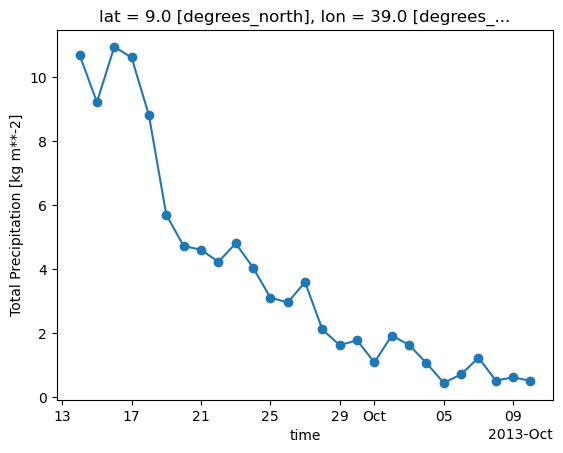

In [19]:
#so, our data are now daily
year="2013"
hcd.sel(time=year).sel(lat=9,lon=39,method="nearest").mean("member").plot(marker="o")

In [20]:
# that is easy - we do it with xESMF

regridder = xe.Regridder(obs, hcd, 'conservative')
obsr = regridder(obs, skipna=True, na_thres=0.9)

regridder = xe.Regridder(hcd, obs, 'bilinear')
hcdr = regridder(hcd, skipna=True, na_thres=0.9)

fcdr = regridder(fcd, skipna=True, na_thres=0.9)

Text(0.5, 0.98, 'just illustrating spatial patterns')

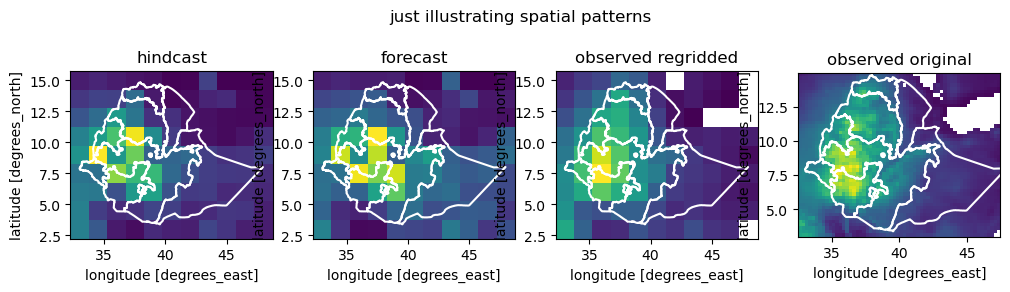

In [21]:
#checking the outcomes

fig=plt.figure(figsize=(12,3))
pl=fig.add_subplot(1,4,1)
hcd.mean(["time","member"]).plot(ax=pl, add_colorbar=False)
vec.boundary.plot(ax=pl,color="white")
pl.set_title("hindcast")

pl=fig.add_subplot(1,4,2)
fcd.mean(["time","member"]).plot(ax=pl, add_colorbar=False)
vec.boundary.plot(ax=pl,color="white")
pl.set_title("forecast")

pl=fig.add_subplot(1,4,3)
obsr.mean(["time"]).plot(ax=pl, add_colorbar=False)
vec.boundary.plot(ax=pl,color="white")
pl.set_title("observed regridded")

pl=fig.add_subplot(1,4,4)
obs.mean(["time"]).plot(ax=pl, add_colorbar=False)
vec.boundary.plot(ax=pl,color="white")
pl.set_title("observed original")

plt.suptitle("just illustrating spatial patterns")

Text(0.5, 0.98, 'just illustrating spatial patterns')

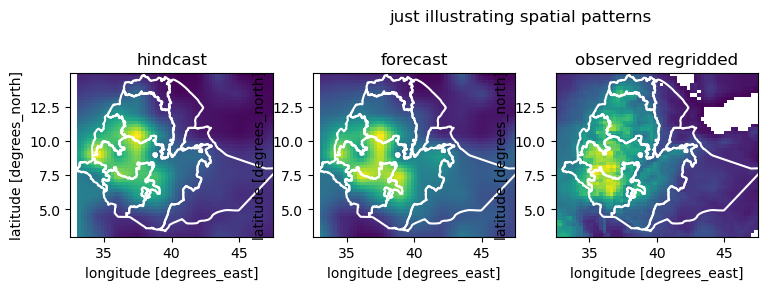

In [22]:
#checking the outcomes

fig=plt.figure(figsize=(12,3))
pl=fig.add_subplot(1,4,1)
hcdr.mean(["time","member"]).plot(ax=pl, add_colorbar=False)
vec.boundary.plot(ax=pl,color="white")
pl.set_title("hindcast")

pl=fig.add_subplot(1,4,2)
fcdr.mean(["time","member"]).plot(ax=pl, add_colorbar=False)
vec.boundary.plot(ax=pl,color="white")
pl.set_title("forecast")

pl=fig.add_subplot(1,4,3)
obs.mean(["time"]).plot(ax=pl, add_colorbar=False)
vec.boundary.plot(ax=pl,color="white")
pl.set_title("observed regridded")

plt.suptitle("just illustrating spatial patterns")

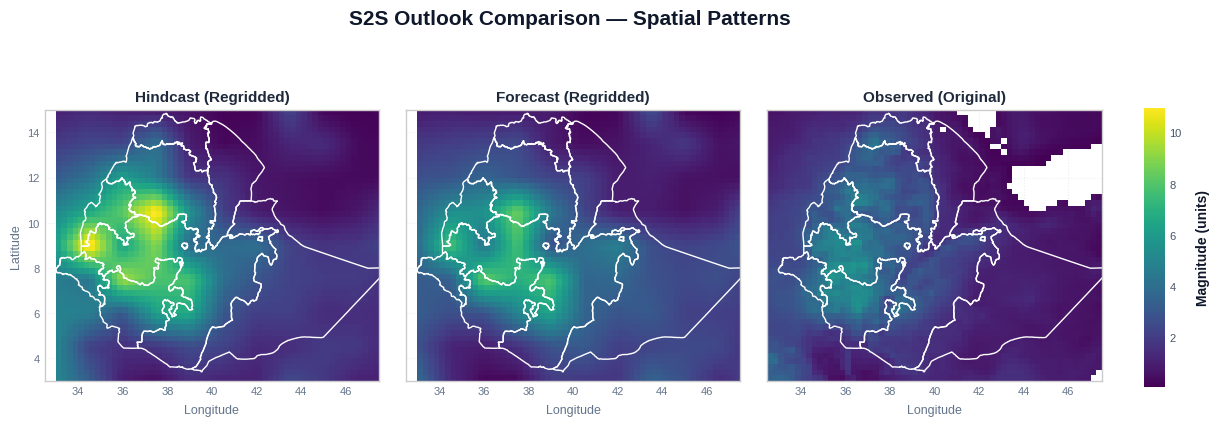

In [23]:
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 1. CALCULATE MEANS & EXTRACT UNIFIED RANGE (The Smart Foundation)
# -------------------------------------------------------------------------
# Pre-calculate the spatial means
mean_hcdr = hcdr.mean(["time", "member"])
mean_fcdr = fcdr.mean(["time", "member"])
mean_obs = obs.mean(["time"])

# Dynamically find global limits across all three datasets for an honest color scale
vmin = min(float(mean_hcdr.min()), float(mean_fcdr.min()), float(mean_obs.min()))
vmax = max(float(mean_hcdr.max()), float(mean_fcdr.max()), float(mean_obs.max()))

# -------------------------------------------------------------------------
# 2. PLOT DESIGN & SETUP (1 Row, 3 Columns)
# -------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Create a 1x3 grid with shared X and Y axes
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True, sharey=True)

fig.suptitle(
    "S2S Outlook Comparison — Spatial Patterns", 
    fontsize=15, weight='bold', color='#0f172a', y=1.02
)

# Standardize plotting arguments (change "viridis" to "Blues" or "YlOrRd" if preferred!)
plot_kwargs = {
    "vmin": vmin,
    "vmax": vmax,
    "cmap": "viridis", 
    "add_colorbar": False
}

# -------------------------------------------------------------------------
# 3. POPULATE SUBPLOTS
# -------------------------------------------------------------------------
# Panel 1: Hindcast (Regridded)
im = mean_hcdr.plot(ax=axes[0], **plot_kwargs)
vec.boundary.plot(ax=axes[0], color="white", linewidth=1.0, zorder=2)
axes[0].set_title("Hindcast (Regridded)", fontsize=11, weight='semibold', color='#1e293b')

# Panel 2: Forecast (Regridded)
mean_fcdr.plot(ax=axes[1], **plot_kwargs)
vec.boundary.plot(ax=axes[1], color="white", linewidth=1.0, zorder=2)
axes[1].set_title("Forecast (Regridded)", fontsize=11, weight='semibold', color='#1e293b')

# Panel 3: Observed (Original Grid)
mean_obs.plot(ax=axes[2], **plot_kwargs)
vec.boundary.plot(ax=axes[2], color="white", linewidth=1.0, zorder=2)
axes[2].set_title("Observed (Original)", fontsize=11, weight='semibold', color='#1e293b')

# -------------------------------------------------------------------------
# 4. SMART AXIS CLEANUP & TIDYING
# -------------------------------------------------------------------------
for i, ax in enumerate(axes):
    # Strip xarray's default verbose axis labels
    ax.set_xlabel("Longitude", fontsize=9, color='#64748b', labelpad=6)
    
    if i == 0:
        ax.set_ylabel("Latitude", fontsize=9, color='#64748b')
    else:
        ax.set_ylabel("") # Hide interior Y-axis labels
        
    ax.tick_params(colors='#64748b', labelsize=8)
    ax.grid(True, linestyle=":", alpha=0.4, color="#cbd5e1")

# -------------------------------------------------------------------------
# 5. SMART COLORBAR (Legend) PLACEMENT
# -------------------------------------------------------------------------
# Adjust subplots to leave perfect breathing room on the right for the colorbar
fig.subplots_adjust(right=0.88, wspace=0.08)

# Define exact, stable coordinates for the colorbar: [left, bottom, width, height]
cbar_ax = fig.add_axes([0.91, 0.18, 0.015, 0.62]) 
cbar = fig.colorbar(im, cax=cbar_ax)

# Style the colorbar beautifully
cbar.set_label("Magnitude (units)", fontsize=10, weight='bold', color='#0f172a', labelpad=10)
cbar.ax.tick_params(labelsize=8, colors='#475569')
cbar.outline.set_visible(False)

plt.show()


In [24]:
#we do not need all observations, only the ones that align with hindcast, so...
hcd_aligned, obs_aligned = xr.align(hcdr, obs, join='inner')

#checking dimensions
hcd.shape, obsr.shape, hcd_aligned.shape, obs_aligned.shape

((540, 22, 9, 11), (7456, 9, 11), (540, 22, 48, 60), (540, 48, 60))

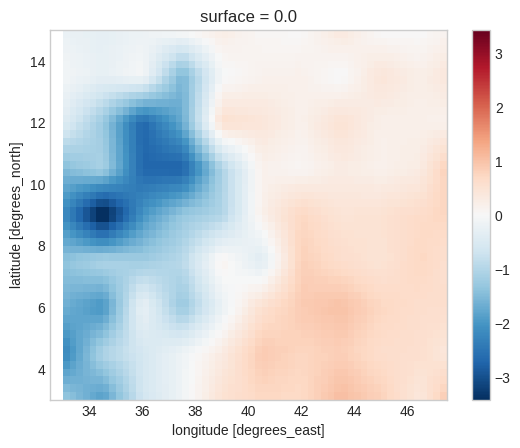

In [25]:
(fcdr.mean(["time","member"])-hcdr.mean(["time","member"])).plot()


In [26]:
hcd_aligned.dims, fc.dims

(('time', 'member', 'lat', 'lon'), ('time', 'member', 'lat', 'lon'))

In [27]:
#finding where cycles start - similar to earlier
isinit = hcd_aligned.time.diff("time") > np.timedelta64(1, "D")
isinit = isinit.reindex(time=hcd_aligned.time, fill_value=True)

#this is length of all hindcast data
n_time=len(isinit)

#finding initialization dates, i.e. first days of each cycle
init_date=hcd_aligned.time[isinit]

#number of cycles
n_init=len(init_date)

#checking if length of data is equal to number of blocks times number of lead times - this will give error if not
assert n_time % n_init == 0, "time length isn't a multiple of the number of initializations — check for partial blocks"

#number of lead time days
n_leadtime = len(isinit) // n_init

assert n_leadtime==len(fc.time), "forecast should have the same number of leadtimes as hindcast but does not — check why"

In [28]:
# now, we can re-align hindast data by lead time

# Block index (0,0,...,0,1,1,...,1,...) and lead_time index (0..29 repeating)
block_id = np.repeat(np.arange(n_init), n_leadtime)
lead_time = np.tile(np.arange(n_leadtime), n_init).astype('timedelta64[D]')

# Attach coords and reshape
temp = hcd_aligned.assign_coords(
    init_date=('time', init_date[block_id].data),
    lead_time=('time', lead_time),
)

#setting indices
hc_lt = temp.set_index(time=['init_date', 'lead_time']).unstack('time')
hc_lt = hc_lt.transpose('init_date', 'lead_time', 'member', 'lat', 'lon')

In [29]:
# the same for observations

# Attach coords and reshape
temp = obs_aligned.assign_coords(
    init_date=('time', init_date[block_id].data),
    lead_time=('time', lead_time),
)
obs_lt = temp.set_index(time=['init_date', 'lead_time']).unstack('time')
obs_lt = obs_lt.transpose('init_date', 'lead_time', 'lat', 'lon')

In [30]:
# and the same for forecast
#we have only one init_date
init_date=fcdr.time[[0]]
block_id = np.repeat([0], n_leadtime)

#and only one set of leadtimes
lead_time=np.arange(n_leadtime).astype('timedelta64[D]')

# Attach coords and reshape
temp = fcdr.assign_coords(
    init_date=('time', init_date[block_id].data),
    lead_time=('time', lead_time),
)

fc_lt = temp.set_index(time=['init_date', 'lead_time']).unstack('time')
fc_lt = fc_lt.transpose('init_date', 'lead_time', 'member','lat', 'lon')


In [31]:
block="7D" #pythonic expression of block size - how many days

obs_block=obs_lt.resample(lead_time=block).sum()
hc_block=hc_lt.resample(lead_time=block).sum()
fc_block=fc_lt.resample(lead_time=block).sum()

#we can change the lead_time coordinate for easier operation - so we will call lead_time through its integer number rather than through timedifference
obs_block["lead_time"]=np.arange(len(obs_block["lead_time"]))
hc_block["lead_time"]=np.arange(len(hc_block["lead_time"]))
fc_block["lead_time"]=np.arange(len(fc_block["lead_time"]))

fc_block

<xarray.DataArray (init_date: 1, lead_time: 4, member: 101, lat: 48, lon: 60)> Size: 9MB
array([[[[[0.00000000e+00, 0.00000000e+00, 7.50569771e+00, ...,
           3.33927711e+00, 4.77679458e+00, 6.21338805e+00],
          [0.00000000e+00, 0.00000000e+00, 6.83166846e+00, ...,
           4.16768995e+00, 5.50038547e+00, 6.83217226e+00],
          [0.00000000e+00, 0.00000000e+00, 6.15767798e+00, ...,
           4.99605541e+00, 6.22393467e+00, 7.45092116e+00],
          ...,
          [0.00000000e+00, 0.00000000e+00, 6.97419584e+00, ...,
           8.14486982e+00, 8.74505554e+00, 9.34504149e+00],
          [0.00000000e+00, 0.00000000e+00, 7.69104903e+00, ...,
           8.82777103e+00, 9.77554599e+00, 1.07231278e+01],
          [0.00000000e+00, 0.00000000e+00, 8.40794333e+00, ...,
           9.51071142e+00, 1.08060954e+01, 1.21012924e+01]],

         [[0.00000000e+00, 0.00000000e+00, 2.27495652e+00, ...,
           1.12383960e+00, 1.72558971e+00, 2.32691961e+00],
          [0.00000000e+00, 0.00000000e+00, 3.00880847e+00, ...,
           1.50142715e+00, 2.06150798e+00, 2.62117562e+00],
          [0.00000000e+00, 0.00000000e+00, 3.74261834e+00, ...,
           1.87899301e+00, 2.39740694e+00, 2.91541486e+00],
...
           2.61946774e+01, 2.53860514e+01, 2.45782099e+01],
          [0.00000000e+00, 0.00000000e+00, 5.62912621e+01, ...,
           2.34019780e+01, 2.24571412e+01, 2.15130389e+01],
          [0.00000000e+00, 0.00000000e+00, 5.71734257e+01, ...,
           2.06091192e+01, 1.95280640e+01, 1.84476932e+01]],

         [[0.00000000e+00, 0.00000000e+00, 2.19778553e+01, ...,
           4.13785183e-02, 6.20280901e-02, 8.25715522e-02],
          [0.00000000e+00, 0.00000000e+00, 2.28215882e+01, ...,
           1.39033657e-01, 1.90060853e-01, 2.40982989e-01],
          [0.00000000e+00, 0.00000000e+00, 2.36652713e+01, ...,
           2.36683207e-01, 3.18086277e-01, 3.99385329e-01],
          ...,
          [0.00000000e+00, 0.00000000e+00, 3.33985775e+00, ...,
           2.01402425e+01, 2.13099822e+01, 2.24804376e+01],
          [0.00000000e+00, 0.00000000e+00, 3.74976995e+00, ...,
           1.74569145e+01, 1.85824409e+01, 1.97086335e+01],
          [0.00000000e+00, 0.00000000e+00, 4.15970574e+00, ...,
           1.47734330e+01, 1.58547431e+01, 1.69366706e+01]]]]],
      shape=(1, 4, 101, 48, 60))
Coordinates:
  * init_date  (init_date) datetime64[ns] 8B 2026-09-15
  * lead_time  (lead_time) int64 32B 0 1 2 3
  * lat        (lat) float64 384B 14.87 14.62 14.37 14.12 ... 3.625 3.375 3.125
  * lon        (lon) float64 480B 32.63 32.88 33.13 33.38 ... 46.88 47.13 47.38
    surface    float64 8B 0.0
Dimensions without coordinates: member
Attributes:
    regrid_method:  bilinear

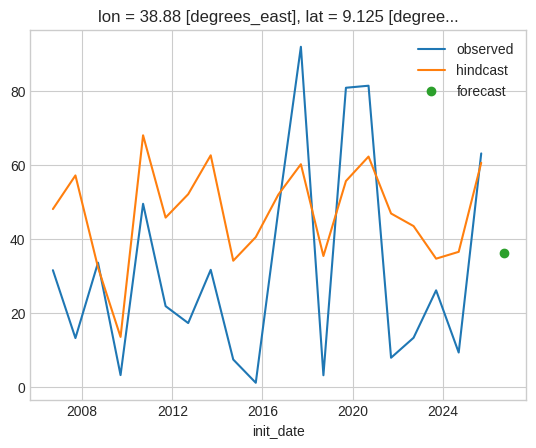

In [32]:
#plotting for a particular lead time and lat lon
lt=0
lat=9
lon=39

obs_block.sel(lead_time=lt).sel(lat=lat,lon=lon, method="nearest").plot(label="observed")
hc_block.sel(lead_time=lt).mean("member").sel(lat=lat,lon=lon, method="nearest").plot(label="hindcast")
data=fc_block.sel(lead_time=lt).mean("member").sel(lat=lat,lon=lon, method="nearest")
plt.plot(data.init_date, data, "o", label="forecast")
plt.legend()

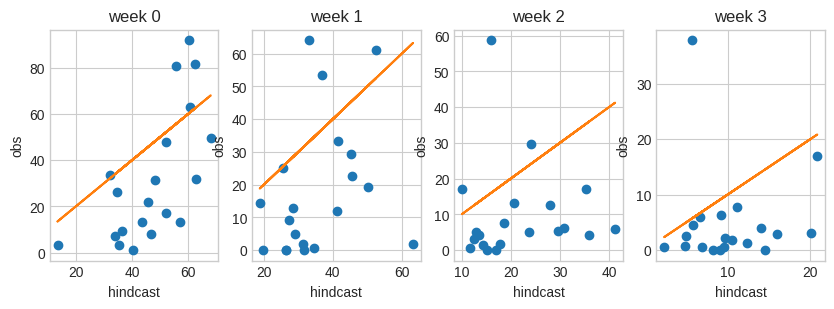

In [33]:
fig=plt.figure(figsize=(10,3))
               
for i,lt in enumerate(range(4)):
    pl=fig.add_subplot(1,4,i+1)

    o=obs_block.sel(lead_time=lt).sel(lat=lat,lon=lon, method="nearest")
    h=hc_block.sel(lead_time=lt).mean("member").sel(lat=lat,lon=lon, method="nearest")
    
    pl.plot(h,o, "o")
    pl.plot(h,h, "-")
    pl.set_ylabel("obs")
    pl.set_xlabel("hindcast")
    
    pl.set_title(f"week {i}")

NameError: name 'hc_bc' is not defined

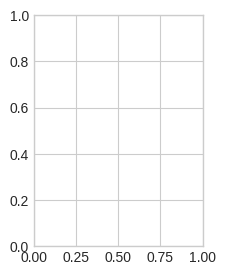

In [34]:
from scipy.stats import pearsonr
fig=plt.figure(figsize=(10,3))
               
for i,lt in enumerate(range(4)):
    pl=fig.add_subplot(1,4,i+1)

    o=obs_block.sel(lead_time=lt).sel(lat=lat,lon=lon, method="nearest")
    h=hc_bc.sel(lead_time=lt).mean("member").sel(lat=lat,lon=lon, method="nearest")
    
    r,p=pearsonr(o,h)
    
    pl.plot(h,o, "o")
    pl.plot(h,h, "-")
    pl.set_ylabel("obs")
    pl.set_xlabel("hindcast")
    
    pl.set_title(f"week {i} {np.round(r,2)}")

In [35]:
def qm_core(hc_1d, ob_1d, x_1d):
    # this is function that actually processes data. it operates on plain 1-D numpy array 
    # it works on empirical quantiles
    # remove NaNs
    hc_1d = hc_1d[~np.isnan(hc_1d)]
    ob_1d = ob_1d[~np.isnan(ob_1d)]
    
    #if received data are only nans, then function returns nans
    if len(hc_1d) == 0 or len(ob_1d) == 0:
        return np.full_like(x_1d, np.nan)

    #sorting reference observed and hindcast
    hc_sorted = np.sort(hc_1d)
    ob_sorted = np.sort(ob_1d)

    #quantiles of both distributions for each point 
    q_hc = np.linspace(0, 1, len(hc_sorted))
    q_ob = np.linspace(0, 1, len(ob_sorted))

    #deriving quantiles corresponding to x from interpolation of the hcst values vs hindcast quantiles function 
    p = np.interp(x_1d, hc_sorted, q_hc)
    
    return np.interp(p, q_ob, ob_sorted)

def bc_simple_qqmapping(forecast,hindcast,observed):
    """
    Apply quantile-quantile mapping bias correction to forecast and hindcast data.

    For each lead time, maps the emiprical distribution of the hindcast and forecast
    to match the observed empirical distribution using quantile mapping. The transfer
    function is derived from the hindcast/observation pair and applied to
    both hindcast and forecast. This is simple quantile mapping based on emiprical 	
    distributions and without extension of tails, and thus by nature bias-corrected forecast 
    maxima/minima will not exceed these in observations.   

    Parameters
    ----------
    forecast : xarray.DataArray
        Forecast data with dimensions (lead_time, lat, lon, init_date, member).
    hindcast : xarray.DataArray
        Hindcast data with dimensions (lead_time, lat, lon, init_date, member).
    observed : xarray.DataArray
        Observed data with dimensions (lead_time, lat, lon, init_date).

    Returns
    -------
    forecast_adjusted : xarray.DataArray
        Bias-corrected forecast, same shape as input forecast.
    hindcast_adjusted : xarray.DataArray
        Bias-corrected hindcast, same shape as input hindcast.

    Notes
    -----
    Member and init_date dimensions are stacked into a single sample dimension
    before applying the quantile mapping, to maximise the sample size used
    for estimating the transfer function.

    The core quantile mapping is performed by a function applied pointwise
    over lat/lon using `xr.apply_ufunc` with dask parallelization support.
    """
    
    #copy of original arrays to store results into
    hindcast_adjusted=hindcast.copy().transpose("lead_time", "lat", "lon", "init_date", "member")
    forecast_adjusted=forecast.copy().transpose("lead_time", "lat", "lon", "init_date", "member")

    #iterating through lead times
    for lead_time in hindcast.lead_time:

        hc=hindcast_adjusted.sel(lead_time=lead_time)
        fc=forecast_adjusted.sel(lead_time=lead_time)
        ob=observed.sel(lead_time=lead_time)


        #pooling across all init_dates
        hc_sample = (
            hc.stack(sample_hc=("member", "init_date"))
        )
        
        # save the index before dropping
        hc_sample_index = hc_sample.sample_hc

        # drop for apply_ufunc
        hc_input = hc_sample.reset_index("sample_hc", drop=True)

        #pooling across all init_dates
        fc_sample = (
            fc.stack(sample_fc=("member", "init_date"))
        )
        
        # save the index before dropping
        fc_sample_index = fc_sample.sample_fc
        
        # drop for apply_ufunc
        fc_input = fc_sample.reset_index("sample_fc", drop=True)
        
        #pooling across all init_dates
        ob_sample = (
            ob.stack(sample_ob=("init_date",))
        )
                
        # drop for apply_ufunc
        ob_input = ob_sample.reset_index("sample_ob", drop=True)

        

        # adjusting hindcast
        hcadj=xr.apply_ufunc(
            qm_core,
            hc_input,
            ob_input,
            hc_input,
            input_core_dims=[["sample_hc"], ["sample_ob"], ["sample_hc"]],
            output_core_dims=[["sample_hc"]],
            vectorize=True,
            dask="parallelized",
            output_dtypes=[hc.dtype],
            join="override",   
        )

        # adjusting forecast
        fcadj=xr.apply_ufunc(
            qm_core,
            hc_input,
            ob_input,
            fc_input,
            input_core_dims=[["sample_hc"], ["sample_ob"], ["sample_fc"]],
            output_core_dims=[["sample_fc"]],
            vectorize=True,
            dask="parallelized",
            output_dtypes=[hc.dtype],
            join="override", 
        )

        # restore index and unstack
        hcadj = hcadj.assign_coords(sample_hc=hc_sample_index)
        hcadj = hcadj.unstack("sample_hc")
        hcadj = hcadj.transpose(*hc.dims)

        fcadj = fcadj.assign_coords(sample_fc=fc_sample_index)
        fcadj = fcadj.unstack("sample_fc")
        fcadj = fcadj.transpose(*fc.dims)
        
        
        #injecting adjusted data into
        hindcast_adjusted.loc[dict(lead_time=lead_time)]=hcadj.data
        forecast_adjusted.loc[dict(lead_time=lead_time)]=fcadj.data

        #adjusting sequence of dimensions
        forecast_adjusted=forecast_adjusted.transpose(*hindcast.dims)
        hindcast_adjusted=hindcast_adjusted.transpose(*forecast.dims)
            
    return forecast_adjusted, hindcast_adjusted


In [36]:
fc_bc,hc_bc=bc_simple_qqmapping(fc_block,hc_block,obs_block)

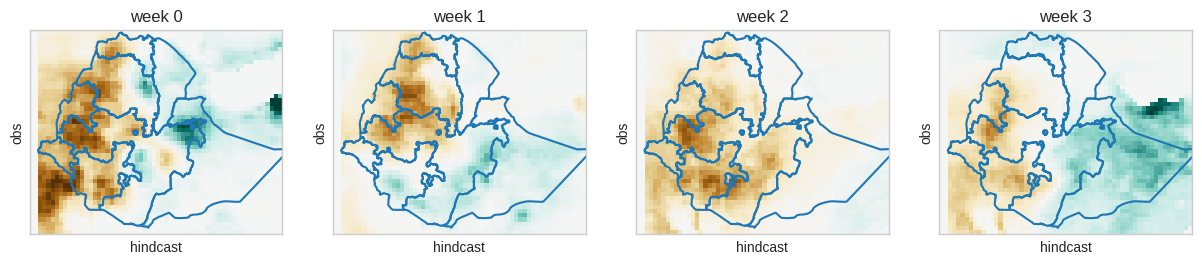

In [37]:
fig=plt.figure(figsize=(15,3))

vmin=-30
vmax=30
cmap="BrBG"

for i,lt in enumerate(range(4)):
    pl=fig.add_subplot(1,4,i+1)

    f=fc_bc.mean("member").isel(init_date=0).sel(lead_time=i)
    h=hc_bc.mean(["member","init_date"]).sel(lead_time=i)
    (f-h).plot(add_colorbar=False, vmin=vmin, vmax=vmax, cmap=cmap)
    
    pl.set_yticks([])
    pl.set_xticks([])
    pl.set_ylabel("obs")
    pl.set_xlabel("hindcast")
    vec.boundary.plot(ax=pl)
    
    pl.set_title(f"week {i}")

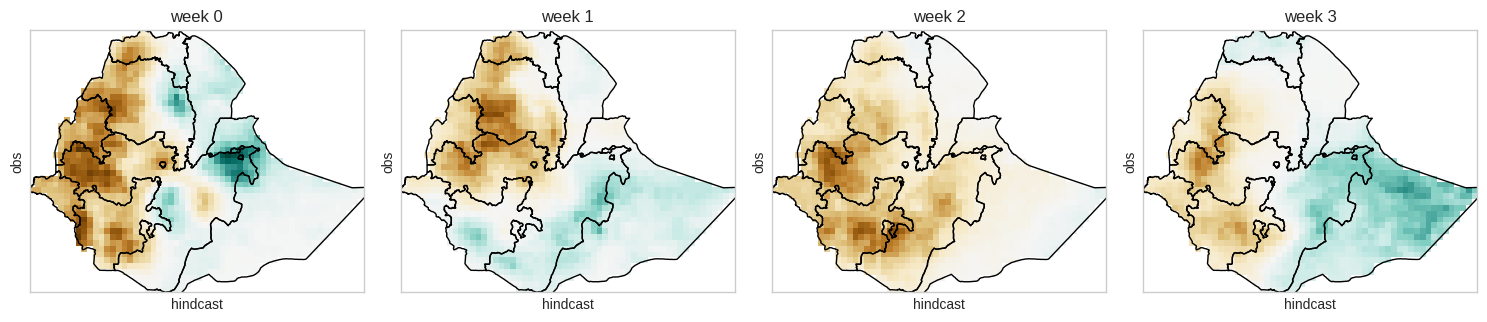

In [38]:
#!pip install rioxarray shapely
import rioxarray
from shapely.geometry import mapping

fig = plt.figure(figsize=(15, 3))

vmin = -30
vmax = 30
cmap = "BrBG"

# Ensure your Xarray data has a CRS defined (e.g., EPSG:4326 for WGS84)
# This must match the CRS of your 'vec' shapefile
fc_bc = fc_bc.rio.write_crs("EPSG:4326")
hc_bc = hc_bc.rio.write_crs("EPSG:4326")

for i, lt in enumerate(range(4)):
    pl = fig.add_subplot(1, 4, i + 1)

    f = fc_bc.mean("member").isel(init_date=0).sel(lead_time=i)
    h = hc_bc.mean(["member", "init_date"]).sel(lead_time=i)
    diff = f - h

    # --- CLIPPING STEP ---
    # Clip the data using the geometry of the shapefile
    # drop=True removes the empty NaN grid cells outside the bounding box
    diff_clipped = diff.rio.clip(vec.geometry.apply(mapping), vec.crs, drop=True)
    
    # Plot the clipped data
    diff_clipped.plot(add_colorbar=False, vmin=vmin, vmax=vmax, cmap=cmap, ax=pl)
    
    pl.set_yticks([])
    pl.set_xticks([])
    pl.set_ylabel("obs")
    pl.set_xlabel("hindcast")
    
    # Plot the boundary outline on top
    vec.boundary.plot(ax=pl, color="black", linewidth=1)
    
    pl.set_title(f"week {i}")

plt.tight_layout()

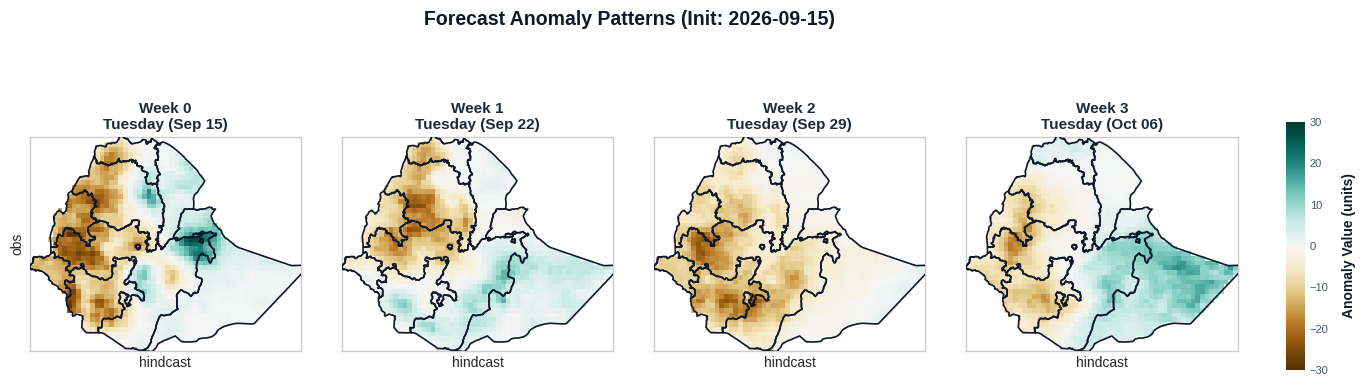

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import rioxarray
from shapely.geometry import mapping

# -------------------------------------------------------------------------
# 1. SETUP GRAPHICS & UNIFIED SCALES
# -------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig = plt.figure(figsize=(16, 4))

vmin = -30
vmax = 30
cmap = "BrBG"

# Ensure CRS is assigned (EPSG:4326 for WGS84 lat/lon coordinates)
fc_bc = fc_bc.rio.write_crs("EPSG:4326")
hc_bc = hc_bc.rio.write_crs("EPSG:4326")

# Extract the base initialization date (using the first index)
base_init_time = pd.to_datetime(fc_bc["init_date"].values[0])

# -------------------------------------------------------------------------
# 2. PANEL GENERATION WITH DYNAMIC WEEKDAYS
# -------------------------------------------------------------------------
for i in range(4):
    pl = fig.add_subplot(1, 4, i + 1)

    # Slice data
    f = fc_bc.mean("member").isel(init_date=0).sel(lead_time=i)
    h = hc_bc.mean(["member", "init_date"]).sel(lead_time=i)
    diff = f - h

    # Calculate the target valid date for this lead time week
    # Assumes 'lead_time' unit is in weeks. If it's in days, swap `weeks=i` to `days=i`
    valid_date = base_init_time + pd.Timedelta(weeks=i)
    weekday_name = valid_date.strftime('%A')      # e.g., "Monday"
    formatted_date = valid_date.strftime('%b %d')  # e.g., "Jul 13"

    # --- CLIPPING STEP ---
    diff_clipped = diff.rio.clip(vec.geometry.apply(mapping), vec.crs, drop=True)
    
    # Plot masked data
    im = diff_clipped.plot(add_colorbar=False, vmin=vmin, vmax=vmax, cmap=cmap, ax=pl)
    
    # Axis style cleanup
    pl.set_yticks([])
    pl.set_xticks([])
    pl.set_ylabel("obs" if i == 0 else "") # Only label the y-axis on the outer left edge
    pl.set_xlabel("hindcast")
    
    # Plot geometry boundaries
    vec.boundary.plot(ax=pl, color="#0f172a", linewidth=1.2, zorder=3)
    
    # Smart, clean titles showing Week, Weekday, and Date
    pl.set_title(f"Week {i}\n{weekday_name} ({formatted_date})", fontsize=11, weight='semibold', color='#1e293b')

# -------------------------------------------------------------------------
# 3. GLOBAL TITLE & ELEGANT COLORBAR
# -------------------------------------------------------------------------
fig.suptitle(
    f"Forecast Anomaly Patterns (Init: {base_init_time.strftime('%Y-%m-%d')})", 
    fontsize=14, weight='bold', color='#0f172a', y=1.08
)

# Position a shared, clean colorbar on the right side
fig.subplots_adjust(right=0.88, wspace=0.15)
cbar_ax = fig.add_axes([0.91, 0.18, 0.012, 0.62]) 
cbar = fig.colorbar(im, cax=cbar_ax)

cbar.set_label("Anomaly Value (units)", fontsize=10, weight='bold', color='#0f172a', labelpad=10)
cbar.ax.tick_params(labelsize=8, colors='#475569')
cbar.outline.set_visible(False)

plt.show()

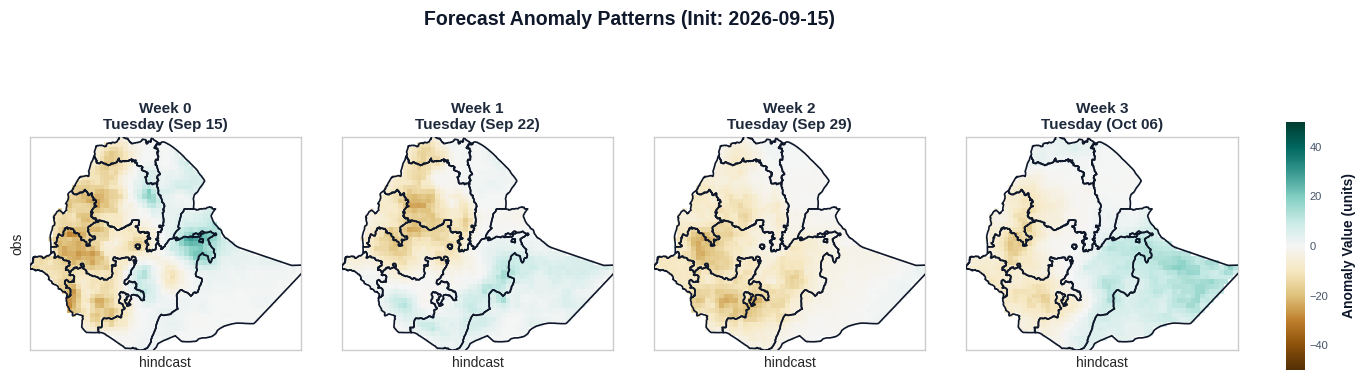

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import rioxarray
from shapely.geometry import mapping

# -------------------------------------------------------------------------
# 1. SETUP GRAPHICS & UNIFIED SCALES
# -------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig = plt.figure(figsize=(16, 4))

vmin = -50
vmax = 50
cmap = "BrBG"

# Ensure CRS is assigned (EPSG:4326 for WGS84 lat/lon coordinates)
fc_bc = fc_bc.rio.write_crs("EPSG:4326")
hc_bc = hc_bc.rio.write_crs("EPSG:4326")

# Extract the base initialization date (using the first index)
base_init_time = pd.to_datetime(fc_bc["init_date"].values[0])

# -------------------------------------------------------------------------
# 2. PANEL GENERATION WITH 7-DAY INTERVAL DATES
# -------------------------------------------------------------------------
for i in range(4):
    pl = fig.add_subplot(1, 4, i + 1)

    # Slice data
    f = fc_bc.mean("member").isel(init_date=0).sel(lead_time=i)
    h = hc_bc.mean(["member", "init_date"]).sel(lead_time=i)
    diff = f - h

    # --- 7-DAY INTERVAL CALCULATION ---
    # Calculates the exact date by shifting the base date by (7 * week_index) days
    valid_date = base_init_time + pd.Timedelta(days=i * 7)
    weekday_name = valid_date.strftime('%A')      # e.g., "Monday"
    formatted_date = valid_date.strftime('%b %d')  # e.g., "Jul 13"

    # --- CLIPPING STEP ---
    diff_clipped = diff.rio.clip(vec.geometry.apply(mapping), vec.crs, drop=True)
    
    # Plot masked data
    im = diff_clipped.plot(add_colorbar=False, vmin=vmin, vmax=vmax, cmap=cmap, ax=pl)
    
    # Axis style cleanup
    pl.set_yticks([])
    pl.set_xticks([])
    pl.set_ylabel("obs" if i == 0 else "")  # Only label the y-axis on the outer left edge
    pl.set_xlabel("hindcast")
    
    # Plot geometry boundaries
    vec.boundary.plot(ax=pl, color="#0f172a", linewidth=1.2, zorder=3)
    
    # Dynamic titles showing Week, Weekday, and Date (spaced by 7 days)
    pl.set_title(f"Week {i}\n{weekday_name} ({formatted_date})", fontsize=11, weight='semibold', color='#1e293b')

# -------------------------------------------------------------------------
# 3. GLOBAL TITLE & ELEGANT COLORBAR
# -------------------------------------------------------------------------
fig.suptitle(
    f"Forecast Anomaly Patterns (Init: {base_init_time.strftime('%Y-%m-%d')})", 
    fontsize=14, weight='bold', color='#0f172a', y=1.08
)

# Position a shared, clean colorbar on the right side
fig.subplots_adjust(right=0.88, wspace=0.15)
cbar_ax = fig.add_axes([0.91, 0.18, 0.012, 0.62]) 
cbar = fig.colorbar(im, cax=cbar_ax)

cbar.set_label("Anomaly Value (units)", fontsize=10, weight='bold', color='#0f172a', labelpad=10)
cbar.ax.tick_params(labelsize=8, colors='#475569')
cbar.outline.set_visible(False)

plt.show()

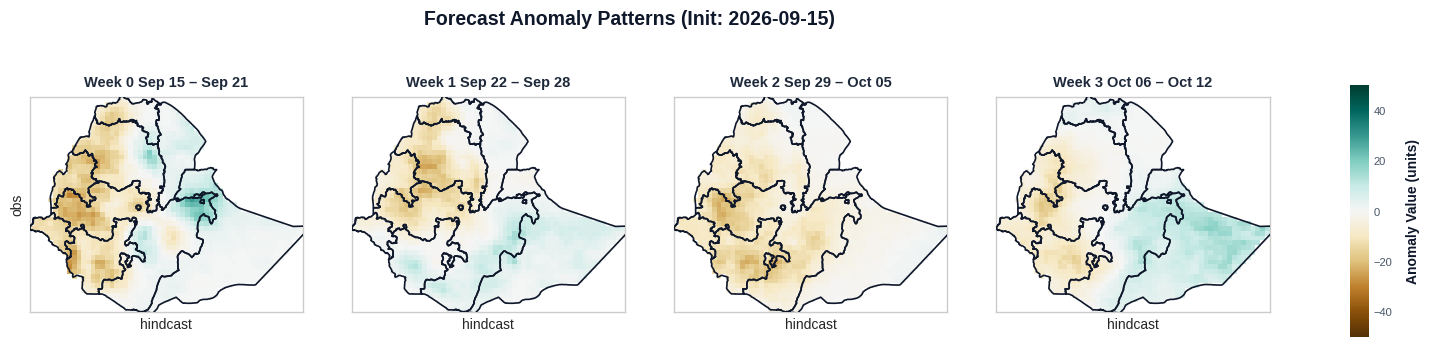

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import rioxarray
from shapely.geometry import mapping

# -------------------------------------------------------------------------
# 1. SETUP GRAPHICS & UNIFIED SCALES
# -------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig = plt.figure(figsize=(16, 4.2))

vmin = -50
vmax = 50
cmap = "BrBG"

# Ensure CRS is assigned (EPSG:4326 for WGS84 lat/lon coordinates)
fc_bc = fc_bc.rio.write_crs("EPSG:4326")
hc_bc = hc_bc.rio.write_crs("EPSG:4326")

# Extract the base initialization date
base_init_time = pd.to_datetime(fc_bc["init_date"].values[0])

# -------------------------------------------------------------------------
# 2. PANEL GENERATION WITH WEEKLY DAY RANGES
# -------------------------------------------------------------------------
for i in range(4):
    pl = fig.add_subplot(1, 4, i + 1)

    # Slice data
    f = fc_bc.mean("member").isel(init_date=0).sel(lead_time=i)
    h = hc_bc.mean(["member", "init_date"]).sel(lead_time=i)
    diff = f - h

    # --- CALCULATE 7-DAY INTERVAL WINDOWS ---
    start_day = i * 7
    end_day = (i * 7) + 6

    # Calculate precise start and end calendar dates for this window
    start_date = base_init_time + pd.Timedelta(days=start_day)
    end_date = base_init_time + pd.Timedelta(days=end_day)
    
    # Format the dates beautifully (e.g., "Jul 13 – Jul 19")
    date_range_str = f"{start_date.strftime('%b %d')} – {end_date.strftime('%b %d')}"

    # --- CLIPPING STEP ---
    diff_clipped = diff.rio.clip(vec.geometry.apply(mapping), vec.crs, drop=True)
    
    # Plot masked data
    im = diff_clipped.plot(add_colorbar=False, vmin=vmin, vmax=vmax, cmap=cmap, ax=pl)
    
    # Axis style cleanup
    pl.set_yticks([])
    pl.set_xticks([])
    pl.set_ylabel("obs" if i == 0 else "")  # Y-axis label on leftmost plot
    pl.set_xlabel("hindcast")
    
    # Plot geometry boundaries
    vec.boundary.plot(ax=pl, color="#0f172a", linewidth=1.2, zorder=3)
    
    # Dynamic titles displaying Week, Day range, and concrete Dates
    pl.set_title(
        f"Week {i} {date_range_str}", 
        fontsize=10.5, weight='semibold', color='#1e293b', pad=8
    )

# -------------------------------------------------------------------------
# 3. GLOBAL TITLE & ELEGANT COLORBAR
# -------------------------------------------------------------------------
fig.suptitle(
    f"Forecast Anomaly Patterns (Init: {base_init_time.strftime('%Y-%m-%d')})", 
    fontsize=14, weight='bold', color='#0f172a', y=0.96
)

# Position a shared, clean colorbar on the right side
fig.subplots_adjust(right=0.9, wspace=0.18)
cbar_ax = fig.add_axes([0.95, 0.18, 0.012, 0.60]) 
cbar = fig.colorbar(im, cax=cbar_ax)

cbar.set_label("Anomaly Value (units)", fontsize=10, weight='bold', color='#0f172a', labelpad=10)
cbar.ax.tick_params(labelsize=8, colors='#475569')
cbar.outline.set_visible(False)

plt.show()

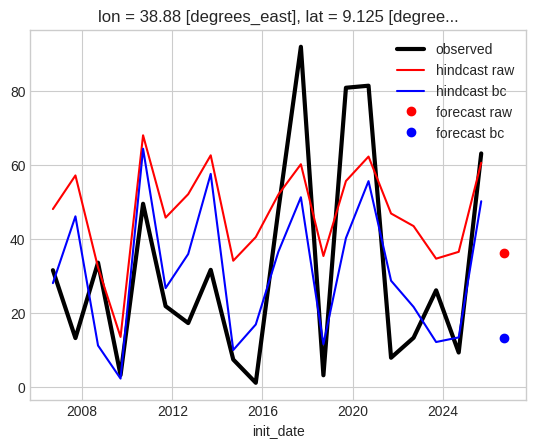

In [42]:
#plotting for a particular lead time and lat lon
lt=0
lat=9
lon=39

obs_block.sel(lead_time=lt).sel(lat=lat,lon=lon, method="nearest").plot(label="observed",color="black", linewidth=3)
hc_block.sel(lead_time=lt).mean("member").sel(lat=lat,lon=lon, method="nearest").plot(label="hindcast raw", color="red")

hc_bc.sel(lead_time=lt).mean("member").sel(lat=lat,lon=lon, method="nearest").plot(label="hindcast bc", color="blue")

data=fc_block.sel(lead_time=lt).mean("member").sel(lat=lat,lon=lon, method="nearest")
plt.plot(data.init_date, data, "o", label="forecast raw", color="red")

data=fc_bc.sel(lead_time=lt).mean("member").sel(lat=lat,lon=lon, method="nearest")
plt.plot(data.init_date, data, "o", label="forecast bc", color="blue")


plt.legend()

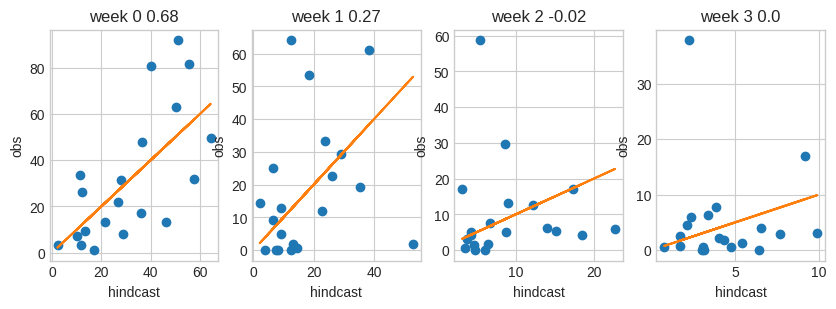

In [43]:
from scipy.stats import pearsonr
fig=plt.figure(figsize=(10,3))
               
for i,lt in enumerate(range(4)):
    pl=fig.add_subplot(1,4,i+1)

    o=obs_block.sel(lead_time=lt).sel(lat=lat,lon=lon, method="nearest")
    h=hc_bc.sel(lead_time=lt).mean("member").sel(lat=lat,lon=lon, method="nearest")
    
    r,p=pearsonr(o,h)
    
    pl.plot(h,o, "o")
    pl.plot(h,h, "-")
    pl.set_ylabel("obs")
    pl.set_xlabel("hindcast")
    
    pl.set_title(f"week {i} {np.round(r,2)}")

In [44]:
#calculate terciles in observational data

q33=obs_block.quantile(0.33,dim="init_date")
q66=obs_block.quantile(0.66,dim="init_date")

q33

<xarray.DataArray 'pr' (lead_time: 4, lat: 48, lon: 60)> Size: 92kB
array([[[ 4.57152062,  5.43201386,  5.93843744, ...,  0.42621272,
          0.45130342,  0.        ],
        [ 6.06329146,  6.66892069,  6.28733381, ...,  0.28218307,
          0.47411925,  1.59418313],
        [ 6.67079045,  6.69187578,  7.30657955, ...,  0.07127714,
          0.71183692,  0.51464664],
        ...,
        [23.59721247, 20.08218475, 18.02254747, ...,  0.        ,
          0.        ,  0.        ],
        [20.67701082, 19.08997358, 19.75493256, ...,  0.        ,
          0.        ,  0.        ],
        [20.71578594, 22.49284571, 23.21132854, ...,  0.        ,
          0.        ,  0.        ]],

       [[ 1.91506076,  3.26898006,  3.04856584, ...,  0.        ,
          0.        ,  0.        ],
        [ 1.67791204,  2.89044336,  2.39643237, ...,  0.03781715,
          0.        ,  0.        ],
        [ 1.32780129,  1.51269364,  2.66169467, ...,  0.3505364 ,
          0.03856126,  0.04105645],
...
        [23.70273865, 20.38466648, 18.05545134, ...,  0.        ,
          0.        ,  0.        ],
        [22.1239691 , 19.79281824, 22.52928947, ...,  0.        ,
          0.        ,  0.        ],
        [25.11004988, 24.74245476, 22.871059  , ...,  0.        ,
          0.        ,  0.        ]],

       [[ 0.        ,  0.        ,  0.48667572, ...,  0.        ,
          0.        ,  0.        ],
        [ 0.        ,  0.        ,  0.2648766 , ...,  0.        ,
          0.        ,  0.        ],
        [ 0.04389157,  0.        ,  0.35824824, ...,  0.        ,
          0.        ,  0.        ],
        ...,
        [16.72682177, 15.90661118, 14.36978535, ...,  4.32412185,
          0.92834561,  0.        ],
        [17.6670125 , 15.94326345, 15.11823228, ...,  0.57811293,
          0.        ,  0.        ],
        [20.31763466, 19.44370228, 18.02167864, ...,  0.81010029,
          0.        ,  0.        ]]], shape=(4, 48, 60))
Coordinates:
  * lead_time  (lead_time) int64 32B 0 1 2 3
  * lat        (lat) float64 384B 14.87 14.62 14.37 14.12 ... 3.625 3.375 3.125
  * lon        (lon) float64 480B 32.63 32.88 33.13 33.38 ... 46.88 47.13 47.38
    quantile   float64 8B 0.33
Attributes:
    units:    mm/day

In [45]:
#count members that fall into terciles
fc_below=(fc_bc<q33).sum("member")/fc_bc.sizes["member"]
hc_below=(hc_bc<q33).sum("member")/fc_bc.sizes["member"]

In [46]:
#plotting for a particular lead time and lat lon
lt=0
lat=9
lon=39

fig=plt.figure(figsize=(10,4))

pl=fig.add_subplot(1,1,1)

obsdata=obs_block.sel(lead_time=lt).sel(lat=lat,lon=lon, method="nearest")
obsdata.plot(label="observed",color="black", linewidth=3, marker="o")

hc_bc.sel(lead_time=lt).mean("member").sel(lat=lat,lon=lon, method="nearest").plot(label="hindcast bc", color="blue")

data=fc_bc.sel(lead_time=lt).mean("member").sel(lat=lat,lon=lon, method="nearest")
pl.plot(data.hcd = regridder(hcdr, skipna=True, na_thres=0.9)init_date, data, "o", label="forecast bc", color="blue")


pl.axhline(q33.sel(lead_time=lt).sel(lat=lat,lon=lon, method="nearest"))
pl.axhline(q66.sel(lead_time=lt).sel(lat=lat,lon=lon, method="nearest"))

plt.legend()
pl.set_ylim(0,150)


pl2=pl.twinx()

data=hc_below.sel(lead_time=lt).sel(lat=lat,lon=lon, method="nearest")

pl2.bar(data.init_date, data.values, width=float(300), alpha=0.7)
pl2.set_ylim(0,0.5)

plt.show()

SyntaxError: expression cannot contain assignment, perhaps you meant "=="? (2983209787.py, line 16)

In [47]:

#plt.bar(data.init_date, data.data, width=86400)


In [48]:
data=obs_block.sel(lead_time=lt).sel(lat=lat,lon=lon, method="nearest").data
np.max(data), np.quantile(data, 0.66)


(np.float32(37.867535), np.float32(3.5376823))

(array([13.,  4.,  1.,  0.,  1.,  0.,  0.,  0.,  0.,  1.]),
 array([ 0.        ,  3.78675342,  7.57350683, 11.36026001, 15.14701366,
        18.93376732, 22.72052002, 26.50727463, 30.29402733, 34.08078003,
        37.86753464]),
 <BarContainer object of 10 artists>)

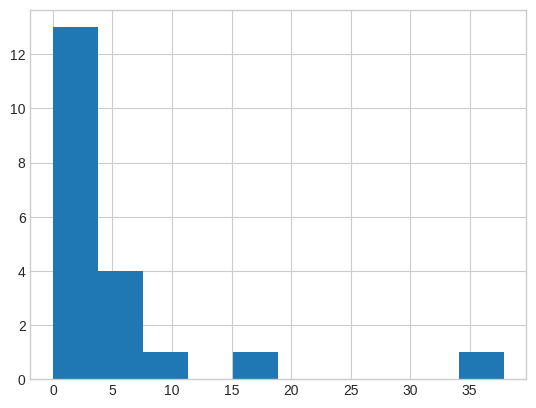

In [49]:
plt.hist(data)